<a href="https://colab.research.google.com/github/SrishanthGorla/SERAI/blob/main/Mapping_an_AI_System_Attack_Surface.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define attack surface threat mapping across the 4 layers
attack_surface_data = [
    {
        "Layer": "Application",
        "Asset": "System Prompt & Orchestrator",
        "Trust Boundary": "TB-1: User <-> Web App",
        "Technique ID": "AML.T0054",
        "Technique Name": "LLM Prompt Injection",
        "Lifecycle Stage": "Inference / Interaction",
        "Likelihood": 3,
        "Impact": 3,
        "Mitigation": "Input guardrails, structural delimiters, parameter boundaries"
    },
    {
        "Layer": "Infrastructure",
        "Asset": "Model Weights & Libraries",
        "Trust Boundary": "TB-3: Internal <-> External Registry",
        "Technique ID": "AML.T0010",
        "Technique Name": "ML Supply Chain Compromise",
        "Lifecycle Stage": "Deployment & Setup",
        "Likelihood": 2,
        "Impact": 3,
        "Mitigation": "Use Safetensors, SBOM audits, signed model weights"
    },
    {
        "Layer": "Data",
        "Asset": "Vector Knowledge Base",
        "Trust Boundary": "TB-4: Data Store <-> Ingestion Pipeline",
        "Technique ID": "AML.T0020",
        "Technique Name": "Poison Training Data",
        "Lifecycle Stage": "Data Ingestion & Storage",
        "Likelihood": 2,
        "Impact": 3,
        "Mitigation": "RBAC on ingestion, hash validation, provenance logging"
    },
    {
        "Layer": "Model",
        "Asset": "Customer Records / Internal Data",
        "Trust Boundary": "TB-2: Orchestrator <-> Model Endpoint",
        "Technique ID": "AML.T0043",
        "Technique Name": "LLM Data Leakage",
        "Lifecycle Stage": "Output Generation",
        "Likelihood": 3,
        "Impact": 2,
        "Mitigation": "Contextual access control, PII scrubbing, response masking"
    },
    {
        "Layer": "Application",
        "Asset": "Inference Compute Endpoints",
        "Trust Boundary": "TB-1: User <-> Web App",
        "Technique ID": "AML.T0029",
        "Technique Name": "Denial of ML Service",
        "Lifecycle Stage": "Production Serving",
        "Likelihood": 3,
        "Impact": 2,
        "Mitigation": "Strict token quotas, request rate-limiting, timeout limits"
    },
    {
        "Layer": "Model",
        "Asset": "Proprietary Model Weights",
        "Trust Boundary": "TB-2: Orchestrator <-> Model Endpoint",
        "Technique ID": "AML.T0024",
        "Technique Name": "Exfiltration via ML Inference API",
        "Lifecycle Stage": "Production Monitoring",
        "Likelihood": 2,
        "Impact": 2,
        "Mitigation": "Query anomaly detection, user prompt velocity bounds"
    },
    {
        "Layer": "Infrastructure",
        "Asset": "API Credential Vault",
        "Trust Boundary": "TB-3: Pipeline <-> Secrets Store",
        "Technique ID": "AML.T0016",
        "Technique Name": "Compromise Infrastructure",
        "Lifecycle Stage": "System Operation",
        "Likelihood": 1,
        "Impact": 3,
        "Mitigation": "Least privilege IAM, short-lived tokens, secret scanning"
    }
]

# Create DataFrame and compute Risk Score
df = pd.DataFrame(attack_surface_data)
df["Risk Score"] = df["Likelihood"] * df["Impact"]

# Assign Risk Classification
def categorize_risk(score):
    if score >= 6:
        return "High"
    elif score >= 3:
        return "Medium"
    else:
        return "Low"

df["Risk Level"] = df["Risk Score"].apply(categorize_risk)

# Sort by Risk Score descending
df = df.sort_values(by="Risk Score", ascending=False).reset_index(drop=True)

# Save to CSV for submission attachments
df.to_csv("ai_attack_surface_mapping.csv", index=False)

print("Attack Surface Mapping Table:")
df[["Layer", "Asset", "Technique ID", "Technique Name", "Likelihood", "Impact", "Risk Score", "Risk Level"]]

Attack Surface Mapping Table:


,Layer,Asset,Technique ID,Technique Name,Likelihood,Impact,Risk Score,Risk Level
0,Application,System Prompt & Orchestrator,AML.T0054,LLM Prompt Injection,3,3,9,High
1,Infrastructure,Model Weights & Libraries,AML.T0010,ML Supply Chain Compromise,2,3,6,High
2,Data,Vector Knowledge Base,AML.T0020,Poison Training Data,2,3,6,High
3,Model,Customer Records / Internal Data,AML.T0043,LLM Data Leakage,3,2,6,High
4,Application,Inference Compute Endpoints,AML.T0029,Denial of ML Service,3,2,6,High
5,Model,Proprietary Model Weights,AML.T0024,Exfiltration via ML Inference API,2,2,4,Medium
6,Infrastructure,API Credential Vault,AML.T0016,Compromise Infrastructure,1,3,3,Medium


In [2]:
# Extract and format the top five risks
top_5_df = df.head(5).copy()
top_5_df.index = [f"Rank {i+1}" for i in range(len(top_5_df))]

print("=" * 80)
print("TOP 5 IDENTIFIED AI SYSTEM RISKS")
print("=" * 80)

for idx, row in top_5_df.iterrows():
    print(f"\n{idx}: [{row['Layer']} Layer] {row['Technique Name']} ({row['Technique ID']})")
    print(f"  - Target Asset     : {row['Asset']}")
    print(f"  - Trust Boundary   : {row['Trust Boundary']}")
    print(f"  - Likelihood/Impact: Likelihood={row['Likelihood']}, Impact={row['Impact']} -> Risk Score: {row['Risk Score']} ({row['Risk Level']})")
    print(f"  - Primary Defense  : {row['Mitigation']}")

TOP 5 IDENTIFIED AI SYSTEM RISKS

Rank 1: [Application Layer] LLM Prompt Injection (AML.T0054)
  - Target Asset     : System Prompt & Orchestrator
  - Trust Boundary   : TB-1: User <-> Web App
  - Likelihood/Impact: Likelihood=3, Impact=3 -> Risk Score: 9 (High)
  - Primary Defense  : Input guardrails, structural delimiters, parameter boundaries

Rank 2: [Infrastructure Layer] ML Supply Chain Compromise (AML.T0010)
  - Target Asset     : Model Weights & Libraries
  - Trust Boundary   : TB-3: Internal <-> External Registry
  - Likelihood/Impact: Likelihood=2, Impact=3 -> Risk Score: 6 (High)
  - Primary Defense  : Use Safetensors, SBOM audits, signed model weights

Rank 3: [Data Layer] Poison Training Data (AML.T0020)
  - Target Asset     : Vector Knowledge Base
  - Trust Boundary   : TB-4: Data Store <-> Ingestion Pipeline
  - Likelihood/Impact: Likelihood=2, Impact=3 -> Risk Score: 6 (High)
  - Primary Defense  : RBAC on ingestion, hash validation, provenance logging

Rank 4: [Model L

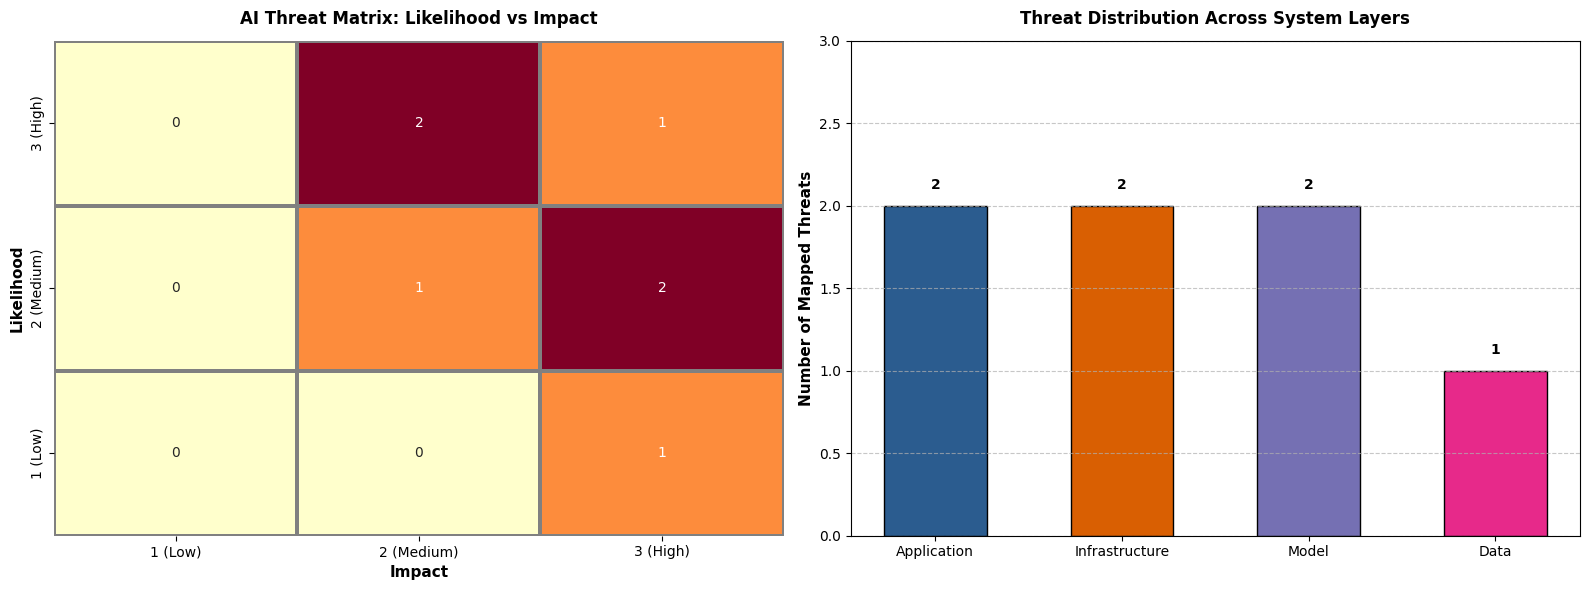

Plots generated and saved as 'attack_surface_risk_visuals.png'


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Likelihood vs Impact 3x3 Matrix Heatmap
matrix_counts = np.zeros((3, 3))
for _, row in df.iterrows():
    # Likelihood on y (indexed 2 down to 0), Impact on x (indexed 0 to 2)
    matrix_counts[3 - row["Likelihood"], row["Impact"] - 1] += 1

sns.heatmap(
    matrix_counts,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    cbar=False,
    xticklabels=["1 (Low)", "2 (Medium)", "3 (High)"],
    yticklabels=["3 (High)", "2 (Medium)", "1 (Low)"],
    ax=axes[0],
    linewidths=1.5,
    linecolor='gray'
)
axes[0].set_title("AI Threat Matrix: Likelihood vs Impact", fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel("Impact", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Likelihood", fontsize=11, fontweight='bold')

# Subplot 2: Threat Count by System Layer
layer_counts = df["Layer"].value_counts()
colors = ["#2b5c8f", "#d95f02", "#7570b3", "#e7298a"]
axes[1].bar(layer_counts.index, layer_counts.values, color=colors[:len(layer_counts)], edgecolor='black', width=0.55)
axes[1].set_title("Threat Distribution Across System Layers", fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel("Number of Mapped Threats", fontsize=11, fontweight='bold')
axes[1].set_ylim(0, max(layer_counts.values) + 1)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate(layer_counts.values):
    axes[1].text(i, v + 0.1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("attack_surface_risk_visuals.png", dpi=300)
plt.show()
print("Plots generated and saved as 'attack_surface_risk_visuals.png'")